### What are we going to do and what is Clustering?

Hello, today i will do some clustering with some economical data. I know this explanation is not enough, yet. 

Basically the main aim of my project is to clustering countries by theri gdp, unepmloyment, trade, inflation and FDI. But what is that thing called clustering? I will explain it now.

Clustering is an **unsupervised learning algorithm** that groups observations by distances based on similarity. But there is different spaces like Euclidean and Manhattann distance measures. 

With K-Means Clustering we are looking the mean value of clusters and place them by the distance measure Euclidean. The important thing here that we are looking for which one is closer to other. 

In [2]:
#importing important libraries that we will use
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score



In [3]:
df = pd.read_excel("P_Data_Extract_From_World_Development_Indicators (14).xlsx")
df.head()

,Time,Time Code,Country Name,Country Code,GDP (constant 2015 US$) [NY.GDP.MKTP.KD],GDP growth (annual %) [NY.GDP.MKTP.KD.ZG],"Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]","Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]",Trade (% of GDP) [NE.TRD.GNFS.ZS],"Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"
0,2023,YR2023,Argentina,ARG,5.916847e+11,-1.855788,133.488936,6.139,26.676951,4.044485
1,2023,YR2023,Austria,AUT,4.246078e+11,-0.786244,7.814134,5.264,115.152915,0.566112
2,2023,YR2023,Belgium,BEL,5.280741e+11,1.561255,4.048679,5.547,165.987441,-0.652734
3,2023,YR2023,Chad,TCD,1.655616e+10,3.998613,10.836357,1.059,46.862649,2.406485
4,2023,YR2023,China,CHN,1.761127e+13,5.416003,0.234837,4.670,36.739150,0.280991


In [4]:
df.describe()

,Time,GDP (constant 2015 US$) [NY.GDP.MKTP.KD],GDP growth (annual %) [NY.GDP.MKTP.KD.ZG],"Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]","Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]",Trade (% of GDP) [NE.TRD.GNFS.ZS],"Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"
count,33.0,3.300000e+01,33.000000,33.000000,33.000000,33.000000,33.000000
mean,2023.0,1.783113e+12,1.543971,12.193383,5.925636,111.732021,-1.866199
std,0.0,4.769928e+12,2.394063,23.536497,2.702625,68.032229,14.373069
min,2023.0,1.655616e+10,-2.744219,0.234837,1.059000,24.929298,-63.154639
25%,2023.0,5.465255e+10,-0.204061,3.842320,3.652000,71.797637,0.566112
50%,2023.0,3.510306e+11,0.922797,7.445416,5.589000,107.277802,2.060898
75%,2023.0,9.110318e+11,3.106796,10.397187,7.335000,135.642989,3.960718
max,2023.0,2.211379e+13,7.832201,133.488936,12.179000,402.566968,12.530612


In [5]:
df.isnull().sum()

Time                                                                                    0
Time Code                                                                               0
Country Name                                                                            0
Country Code                                                                            0
GDP (constant 2015 US$) [NY.GDP.MKTP.KD]                                                0
GDP growth (annual %) [NY.GDP.MKTP.KD.ZG]                                               0
Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]                                  0
Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]    0
Trade (% of GDP) [NE.TRD.GNFS.ZS]                                                       0
Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]                0
dtype: int64

In [6]:
df.columns

Index(['Time', 'Time Code', 'Country Name', 'Country Code',
       'GDP (constant 2015 US$) [NY.GDP.MKTP.KD]',
       'GDP growth (annual %) [NY.GDP.MKTP.KD.ZG]',
       'Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]',
       'Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]',
       'Trade (% of GDP) [NE.TRD.GNFS.ZS]',
       'Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]'],
      dtype='object')

In [7]:

is_numeric = pd.api.types.is_numeric_dtype(df["Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"])

print(is_numeric)  # Returns True or False

True


<AxesSubplot:xlabel='GDP growth (annual %) [NY.GDP.MKTP.KD.ZG]', ylabel='Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]'>

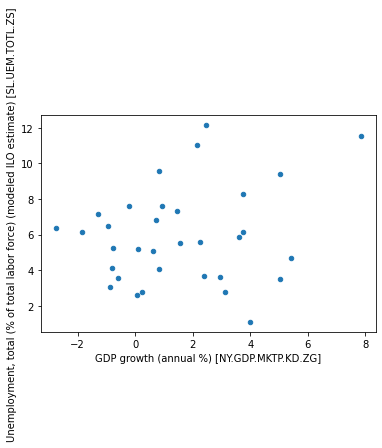

In [8]:
# Pass the column name strings directly, not df['column']
df.plot(
    kind="scatter",
    x="GDP growth (annual %) [NY.GDP.MKTP.KD.ZG]",
    y="Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]",
)

As you can see that this is the most basic graph a person ever could. So here we will make a little bit advanced one. We want to see which country is where and we will have a color map for that. Basically we will see how will it be clustered before we perform any k-means clustering.

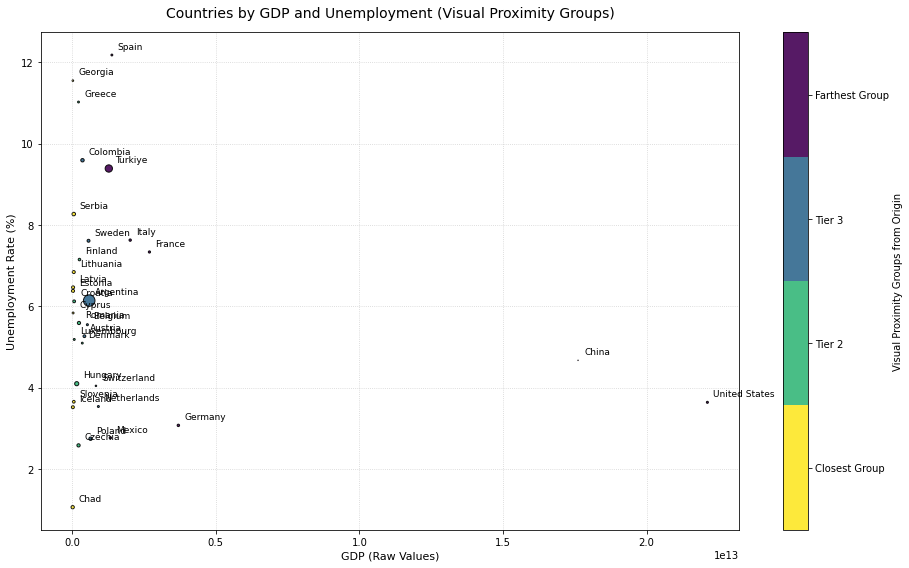

In [9]:
from matplotlib.colors import ListedColormap
#I want to see with normal distance without Euclidean space like when we are going to do with K-Means
df["distance"] = np.sqrt(df["GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"]**2 + df["Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"]**2)

#thewn we will create 4 groups, like clusters to see which country falls in which group in the graph

df["distance_tier"] = pd.qcut(
    df["distance"],
    q=4,
    labels = [0,1,2,3]
)

#setting up the plot 
plt.figure(figsize=(13,8))

#color mapping
cmap = plt.cm.get_cmap("viridis_r",4)

#scatter plot, but size will be inflation
scatter = plt.scatter(
    df["GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"],df["Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"],
    c = df["distance_tier"].astype(int),
    cmap = cmap,
    s = df["Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"],
    edgecolors= "black",
    alpha = 0.9
)

#want to see the labels of countries
for i, row in df.iterrows():
    plt.annotate(
        row["Country Name"],
        (
        row["GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"],
        row["Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"]
        ),
        xytext=(6,6),textcoords="offset points",
        fontsize=9,
        fontweight="medium"
        
    )
    
#formatting the legend/colorbar
cbar = plt.colorbar(scatter, ticks=[0.375, 1.125, 1.875, 2.625])
cbar.ax.set_yticklabels(['Closest Group', 'Tier 2', 'Tier 3', 'Farthest Group'])
cbar.set_label('Visual Proximity Groups from Origin', fontsize=10)

plt.title('Countries by GDP and Unemployment (Visual Proximity Groups)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Values)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Is this a good graph? Ofcourse not. But does it gives us some information? Yes. Here we can see that United states and China are the big outliers that makes our graph look very bad. We can change this problem by normalize gdp and other indicators. With this it all will look kind of alike but the reason I was insisting to show you this graph is to look at the data raw and understand whats going on exactly without normalizing.


# Min-Max Normalization (0 to 1 scale) for X and Y
x_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
y_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"

df['X_norm'] = (df[x_col] - df[x_col].min()) / (df[x_col].max() - df[x_col].min())
df['Y_norm'] = (df[y_col] - df[y_col].min()) / (df[y_col].max() - df[y_col].min())

# 2. Calculate Euclidean distance from the normalized origin (0, 0)
df['Norm_Distance'] = np.sqrt(df['X_norm']**2 + df['Y_norm']**2)

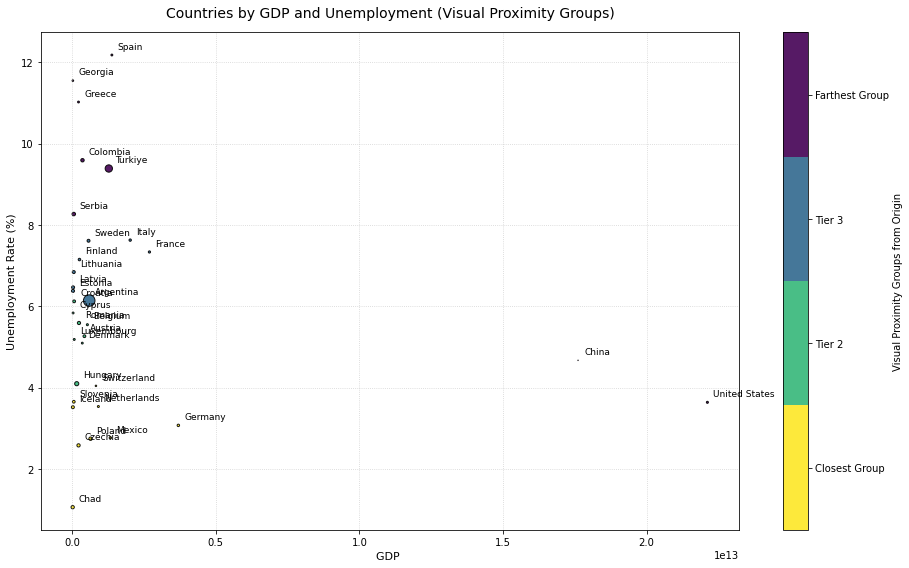

In [10]:
#min/maxing x and y values
x_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
y_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"

df["X_norm"] = (df[x_col]-df[x_col].min()) / (df[x_col].max()-df[x_col].min())
df["Y_norm"] = (df[y_col] - df[y_col].min()) / (df[y_col].max()-df[y_col].min())



df["normalized_distance"] = np.sqrt(df["X_norm"]**2 + df["Y_norm"]**2)

#thewn we will create 4 groups, like clusters to see which country falls in which group in the graph

df["normalized_distance_tier"] = pd.qcut(
    df["normalized_distance"],
    q=4,
    labels = [0,1,2,3]
)

#setting up the plot 
plt.figure(figsize=(13,8))

#color mapping
cmap = plt.cm.get_cmap("viridis_r",4)

#scatter plot, but size will be inflation
scatter = plt.scatter(
    df["GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"],df["Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"],
    c = df["normalized_distance_tier"].astype(int),
    cmap = cmap,
    s = df["Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"],
    edgecolors= "black",
    alpha = 0.9
)

#want to see the labels of countries
for i, row in df.iterrows():
    plt.annotate(
        row["Country Name"],
        (
        row[x_col],
        row[y_col]
        ),
        xytext=(6,6),textcoords="offset points",
        fontsize=9,
        fontweight="medium"
        
    )
    
#formatting the legend/colorbar
cbar = plt.colorbar(scatter, ticks=[0.375, 1.125, 1.875, 2.625])
cbar.ax.set_yticklabels(['Closest Group', 'Tier 2', 'Tier 3', 'Farthest Group'])
cbar.set_label('Visual Proximity Groups from Origin', fontsize=10)

plt.title('Countries by GDP and Unemployment (Visual Proximity Groups)', fontsize=14, pad=15)
plt.xlabel('GDP ', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Even though I normalized the X and Y, China and United States are outliers so I will drop them from the data and again do the chart.

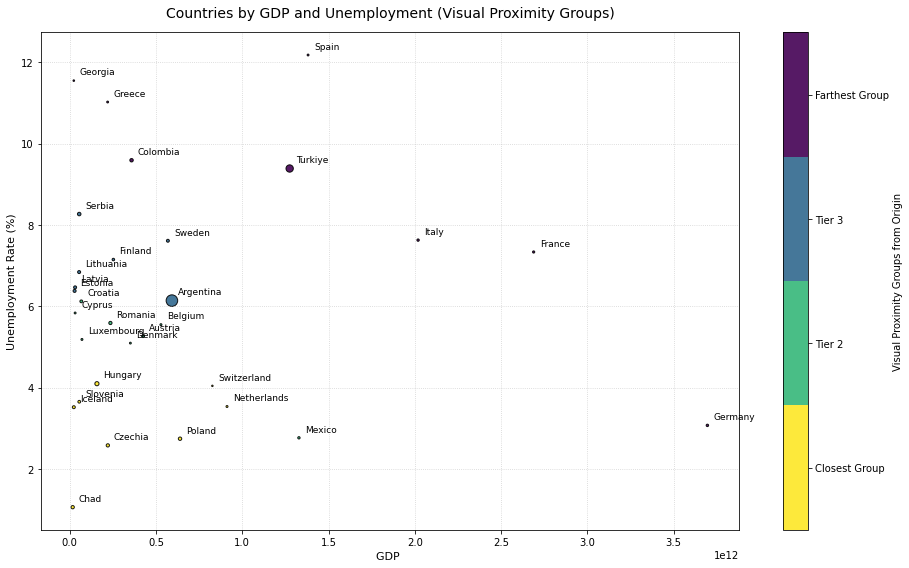

In [11]:
countries_to_exclude = ['United States', 'China']
df_filtered = df[~df['Country Name'].isin(countries_to_exclude)].copy()

x_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
y_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"

df_filtered["X_norm"] = (df_filtered[x_col]-df_filtered[x_col].min()) / (df_filtered[x_col].max()-df_filtered[x_col].min())
df_filtered["Y_norm"] = (df_filtered[y_col] - df_filtered[y_col].min()) / (df_filtered[y_col].max()-df_filtered[y_col].min())



df_filtered["normalized_distance"] = np.sqrt(df_filtered["X_norm"]**2 + df_filtered["Y_norm"]**2)

#thewn we will create 4 groups, like clusters to see which country falls in which group in the graph

df_filtered["normalized_distance_tier"] = pd.qcut(
    df_filtered["normalized_distance"],
    q=4,
    labels = [0,1,2,3]
)

#setting up the plot 
plt.figure(figsize=(13,8))

#color mapping
cmap = plt.cm.get_cmap("viridis_r",4)

#scatter plot, but size will be inflation
scatter = plt.scatter(
    df_filtered["GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"],df_filtered["Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"],
    c = df_filtered["normalized_distance_tier"].astype(int),
    cmap = cmap,
    s = df_filtered["Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"],
    edgecolors= "black",
    alpha = 0.9
)

#want to see the labels of countries
for i, row in df_filtered.iterrows():
    plt.annotate(
        row["Country Name"],
        (
        row[x_col],
        row[y_col]
        ),
        xytext=(6,6),textcoords="offset points",
        fontsize=9,
        fontweight="medium"
        
    )
    
#formatting the legend/colorbar
cbar = plt.colorbar(scatter, ticks=[0.375, 1.125, 1.875, 2.625])
cbar.ax.set_yticklabels(['Closest Group', 'Tier 2', 'Tier 3', 'Farthest Group'])
cbar.set_label('Visual Proximity Groups from Origin', fontsize=10)

plt.title('Countries by GDP and Unemployment (Visual Proximity Groups)', fontsize=14, pad=15)
plt.xlabel('GDP ', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


This graph is looking better than oter but still we can see that Germany,France and Italy are kind-of-outliers. We need a K-means algorithm to see how will it cluster this data. In my opinion, there will be 4-5 clusters. So I will go for K-means but I need to use a standart scaler because GDP data is in millions so distance measures can be really confused.

          K-MEANS CLUSTERING RESULTS (4 CLUSTERS)          

cluster 1 (14 countries):
   • Argentina       (GDP: 591,684,674,129, Unemp: 6.1%)
   • Austria         (GDP: 424,607,814,489, Unemp: 5.3%)
   • Belgium         (GDP: 528,074,098,662, Unemp: 5.5%)
   • Croatia         (GDP: 66,484,829,952, Unemp: 6.1%)
   • Cyprus          (GDP: 30,668,288,121, Unemp: 5.8%)
   • Denmark         (GDP: 351,030,642,724, Unemp: 5.1%)
   • Estonia         (GDP: 27,578,887,219, Unemp: 6.4%)
   • Finland         (GDP: 252,373,129,874, Unemp: 7.1%)
   • Latvia          (GDP: 30,571,453,786, Unemp: 6.5%)
   • Lithuania       (GDP: 53,839,146,914, Unemp: 6.8%)
   • Luxembourg      (GDP: 70,256,893,052, Unemp: 5.2%)
   • Romania         (GDP: 235,229,078,940, Unemp: 5.6%)
   • Serbia          (GDP: 54,366,256,510, Unemp: 8.3%)
   • Sweden          (GDP: 568,322,714,848, Unemp: 7.6%)

cluster 2 (3 countries):
   • France          (GDP: 2,688,358,302,961, Unemp: 7.3%)
   • Germany         (GDP: 3,695,372,

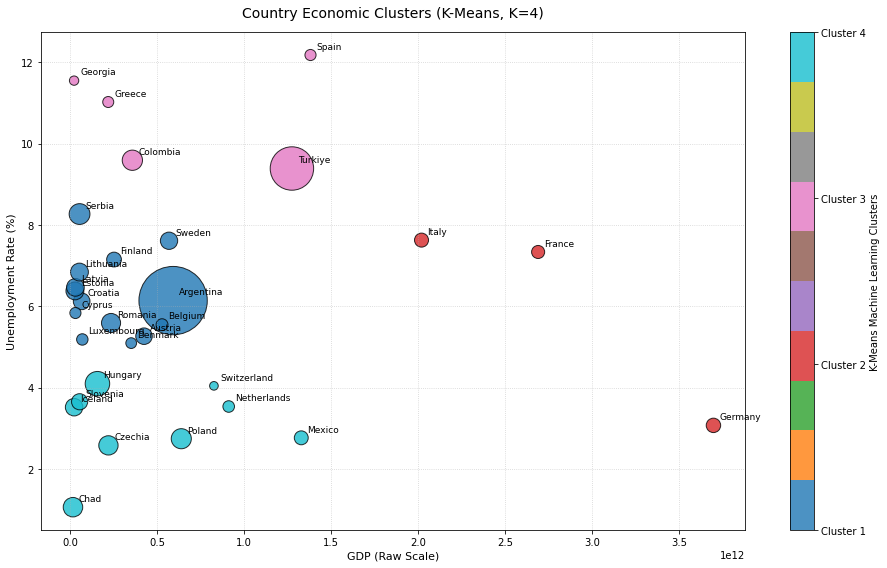

In [12]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

x_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
y_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
size_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"

#creating a cluster dataframe
df_cluster = df_filtered.dropna(subset=[x_col, y_col, size_col, "Country Name"]).copy()

scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_cluster[[x_col,y_col]])

#choosing k
k=4
kmeans = KMeans(n_clusters=k,random_state=42,n_init=10) #we will have 4 clusters and number of itearions for a single algorithm is 10

df_cluster["Cluster"] = kmeans.fit_predict(scaled_features)

# printing a structured text list of countries in each cluster
print("=" * 60)
print(f"          K-MEANS CLUSTERING RESULTS ({k} CLUSTERS)          ")
print("=" * 60)
for cluster_id in range(k):
    cluster_countries = df_cluster[df_cluster['Cluster'] == cluster_id]
    print(f"\ncluster {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        print(f"   • {row['Country Name']:<15} (GDP: {row[x_col]:,.0f}, Unemp: {row[y_col]:.1f}%)")
print("-" * 60)

plt.figure(figsize=(13, 8))

# use a qualitative colormap built for discrete categories (like 'Set1', 'tab10', or 'viridis')
scatter = plt.scatter(
    df_cluster[x_col], 
    df_cluster[y_col], 
    c=df_cluster['Cluster'], 
    cmap='tab10', 
    s=df_cluster[size_col] * 35,  # Sized by inflation
    edgecolors='black', 
    alpha=0.8
)

# annotate each country label
for _, row in df_cluster.iterrows():
    plt.annotate(
        row["Country Name"], 
        (row[x_col], row[y_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )

# formatting
cbar = plt.colorbar(scatter, ticks=range(k))
cbar.ax.set_yticklabels([f'Cluster {i+1}' for i in range(k)])
cbar.set_label('K-Means Machine Learning Clusters', fontsize=10)

plt.title(f'Country Economic Clusters (K-Means, K={k})', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

As you can see the clusters and the graph, it is not possible this is to be for real because just look at that Chad and Switzerland are in the same group. There might be 3 reasons for that :

    * We need to convert GDP to logarithmic version, when GDP is logarithmic it can not have high values and it will gives us a better graph and clustering.
    
    * Also we can increase k to 5 or 6, but before that may be we have to look for elbow method to see which number is more suitable.
    
    * Or if anything works we will use agglomerative (hierarchical) clustering.

      HIERARCHICAL CLUSTERING RESULTS (5 CLUSTERS)      

Cluster 1 (8 countries):
   • Croatia         (GDP: $66,484,829,952, Unemp: 6.1%)
   • Cyprus          (GDP: $30,668,288,121, Unemp: 5.8%)
   • Estonia         (GDP: $27,578,887,219, Unemp: 6.4%)
   • Georgia         (GDP: $22,963,990,777, Unemp: 11.5%)
   • Latvia          (GDP: $30,571,453,786, Unemp: 6.5%)
   • Lithuania       (GDP: $53,839,146,914, Unemp: 6.8%)
   • Luxembourg      (GDP: $70,256,893,052, Unemp: 5.2%)
   • Serbia          (GDP: $54,366,256,510, Unemp: 8.3%)

Cluster 2 (5 countries):
   • Chad            (GDP: $16,556,157,862, Unemp: 1.1%)
   • Czechia         (GDP: $220,242,240,981, Unemp: 2.6%)
   • Hungary         (GDP: $157,072,489,604, Unemp: 4.1%)
   • Iceland         (GDP: $23,121,173,216, Unemp: 3.5%)
   • Slovenia        (GDP: $54,652,553,126, Unemp: 3.7%)

Cluster 3 (6 countries):
   • Colombia        (GDP: $357,739,280,193, Unemp: 9.6%)
   • France          (GDP: $2,688,358,302,961, Unemp: 7.3%)
   

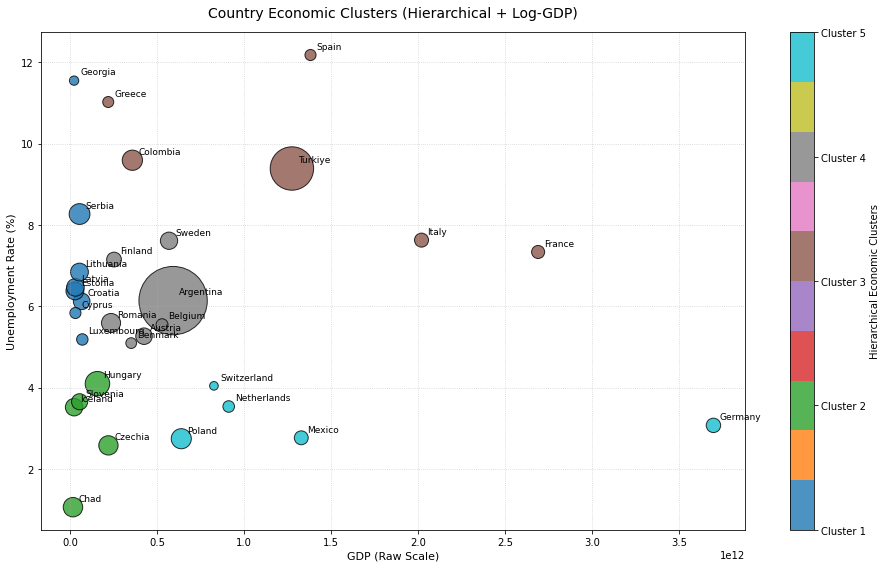

In [13]:
#We will start with first approach, making gdp a logarithmic variable 
from sklearn.cluster import AgglomerativeClustering
# 1. Define your columns
x_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
y_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
size_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"

df_cluster = df_filtered.dropna(subset=[x_col, y_col, size_col, "Country Name"]).copy()

# 2. LOG-TRANSFORM GDP to handle the massive scale differences properly
df_cluster['Log_GDP'] = np.log(df_cluster[x_col])

# 3. Scale the features (Log GDP and Unemployment)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_cluster[['Log_GDP', y_col]])

# 4. Use Agglomerative (Hierarchical) Clustering instead of K-Means
n_clusters = 5  # Let's try 5 clusters to give more nuance
clustering = AgglomerativeClustering(n_clusters=n_clusters, affinity='euclidean', linkage='ward')
df_cluster['Cluster'] = clustering.fit_predict(scaled_features)

# 5. Print out the new logical groupings
print("=" * 65)
print(f"      HIERARCHICAL CLUSTERING RESULTS ({n_clusters} CLUSTERS)      ")
print("=" * 65)
for cluster_id in range(n_clusters):
    cluster_countries = df_cluster[df_cluster['Cluster'] == cluster_id]
    print(f"\nCluster {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        print(f"   • {row['Country Name']:<15} (GDP: ${row[x_col]:,.0f}, Unemp: {row[y_col]:.1f}%)")
print("-" * 65)

# 6. Plot the results
plt.figure(figsize=(13, 8))

scatter = plt.scatter(
    df_cluster[x_col], 
    df_cluster[y_col], 
    c=df_cluster['Cluster'], 
    cmap='tab10', 
    s=df_cluster[size_col] * 35,  
    edgecolors='black', 
    alpha=0.8
)

for _, row in df_cluster.iterrows():
    plt.annotate(
        row["Country Name"], 
        (row[x_col], row[y_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )

cbar = plt.colorbar(scatter, ticks=range(n_clusters))
cbar.ax.set_yticklabels([f'Cluster {i+1}' for i in range(n_clusters)])
cbar.set_label('Hierarchical Economic Clusters', fontsize=10)

plt.title('Country Economic Clusters (Hierarchical + Log-GDP)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

This graph and our results are way much better than the first one but still I feel like something is off. For example Chad's cluster group does not look suitable. I think reason for that problem that is I am using total GDP, to have a better grasp and graph we need to use per capita GDP, because total GDP is most of the time is highly skewed and this kind of problems happen. And the reason why Chad is with other higher tier economies is thta it has a very low unemployment percentage.

My problem is that I don't have GDP per capita but I have annual GDP growth data, which is quite good because I don't have to use any logarithmic variables and no need to normalize GDP column.It also shows Okun's Law which is a microeconomics law that states inverse relationship with economic expansion and unemployment. And for final we can see a behavioral grouping instead of clustering countries by how rich they are. We can see the country's current economic performance and bussines cycles.

      HIERARCHICAL CLUSTERING RESULTS (5 CLUSTERS)      

Cluster 1 (5 countries):
   • Georgia         (GDP: $8, Unemp: 11.5%)
   • Greece          (GDP: $2, Unemp: 11.0%)
   • Serbia          (GDP: $4, Unemp: 8.3%)
   • Spain           (GDP: $2, Unemp: 12.2%)
   • Turkiye         (GDP: $5, Unemp: 9.4%)

Cluster 2 (9 countries):
   • Austria         (GDP: $-1, Unemp: 5.3%)
   • Denmark         (GDP: $1, Unemp: 5.1%)
   • Czechia         (GDP: $0, Unemp: 2.6%)
   • Germany         (GDP: $-1, Unemp: 3.1%)
   • Hungary         (GDP: $-1, Unemp: 4.1%)
   • Luxembourg      (GDP: $0, Unemp: 5.2%)
   • Netherlands     (GDP: $-1, Unemp: 3.5%)
   • Poland          (GDP: $0, Unemp: 2.7%)
   • Switzerland     (GDP: $1, Unemp: 4.0%)

Cluster 3 (8 countries):
   • Belgium         (GDP: $2, Unemp: 5.5%)
   • Croatia         (GDP: $4, Unemp: 6.1%)
   • Colombia        (GDP: $1, Unemp: 9.6%)
   • Cyprus          (GDP: $4, Unemp: 5.8%)
   • France          (GDP: $1, Unemp: 7.3%)
   • Italy           (

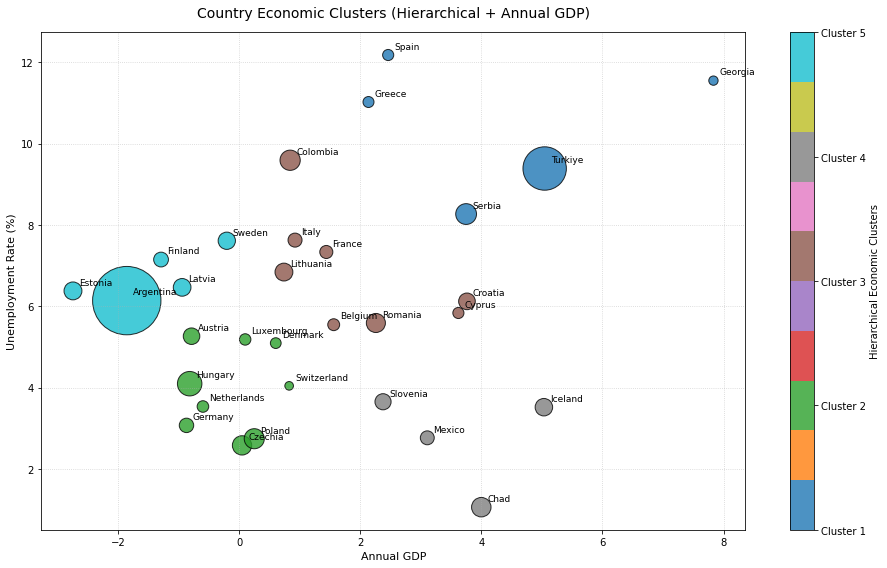

In [14]:

# 1. Define your columns
x_col = "GDP growth (annual %) [NY.GDP.MKTP.KD.ZG]"
y_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
size_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"

df_cluster = df_filtered.dropna(subset=[x_col, y_col, size_col, "Country Name"]).copy()


# 3. Scale the features (Log GDP and Unemployment)
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_cluster[[x_col, y_col]])

# 4. Use Agglomerative (Hierarchical) Clustering instead of K-Means
n_clusters = 5  # Let's try 5 clusters to give more nuance
clustering = AgglomerativeClustering(n_clusters=n_clusters, affinity='euclidean', linkage='ward')
df_cluster['Cluster'] = clustering.fit_predict(scaled_features)

# 5. Print out the new logical groupings
print("=" * 65)
print(f"      HIERARCHICAL CLUSTERING RESULTS ({n_clusters} CLUSTERS)      ")
print("=" * 65)
for cluster_id in range(n_clusters):
    cluster_countries = df_cluster[df_cluster['Cluster'] == cluster_id]
    print(f"\nCluster {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        print(f"   • {row['Country Name']:<15} (GDP: ${row[x_col]:,.0f}, Unemp: {row[y_col]:.1f}%)")
print("-" * 65)

# 6. Plot the results
plt.figure(figsize=(13, 8))

scatter = plt.scatter(
    df_cluster[x_col], 
    df_cluster[y_col], 
    c=df_cluster['Cluster'], 
    cmap='tab10', 
    s=df_cluster[size_col] * 35,  
    edgecolors='black', 
    alpha=0.8
)

for _, row in df_cluster.iterrows():
    plt.annotate(
        row["Country Name"], 
        (row[x_col], row[y_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )

cbar = plt.colorbar(scatter, ticks=range(n_clusters))
cbar.ax.set_yticklabels([f'Cluster {i+1}' for i in range(n_clusters)])
cbar.set_label('Hierarchical Economic Clusters', fontsize=10)

plt.title('Country Economic Clusters (Hierarchical + Annual GDP)', fontsize=14, pad=15)
plt.xlabel("Annual GDP", fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

At first when you look at the graph it is like OK, not that bad but if you really look at the results and may be a little bit closer to graph you can see that it is really bad I mean Argentina with Baltic/Nordic countries? I don't even start with Columbia being in the same group as France and Italy. I think that the reason for that is we dont have enough clusters so I can increase the number of k. And another of my explanation of this problem is that we have annual growth so this means bigger economies can not grow as much as small economies. So theirs annual growth will be higher than expected. This is an actual macroeconomic theory which is called Solow-Svan model, or convergence theory.

May be we should try to use more than just tree indicators but more to see what's underlying all of that economic data.

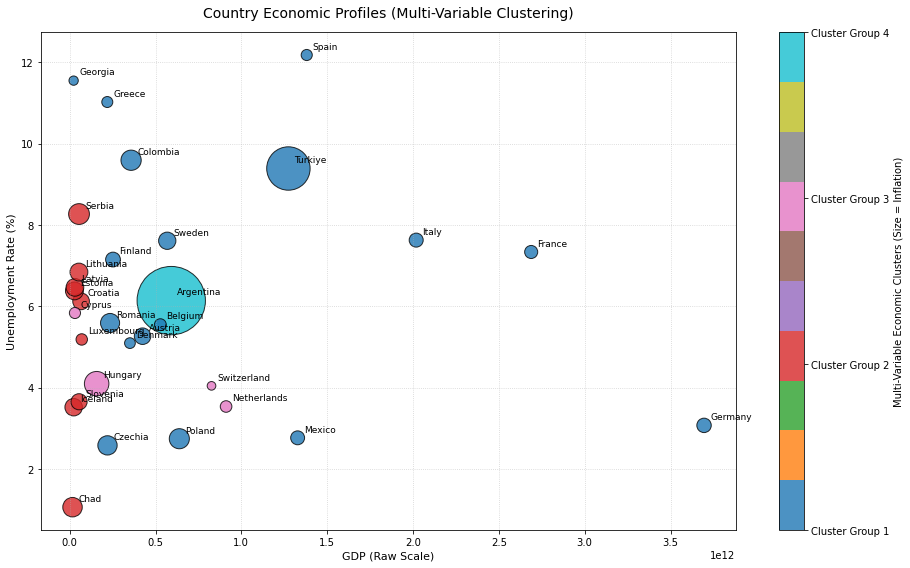

In [16]:
from sklearn.impute import SimpleImputer

# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]" # Replace if you use a different 4th indicator

# Make a working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

# Features used for the machine learning model (all 4 dimensions)
model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 2. Impute missing values (so no countries get dropped)
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

# 3. Scale all features equally
scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Run Hierarchical Clustering (let's use 4 clusters)
n_clusters = 4
clustering = AgglomerativeClustering(n_clusters=n_clusters, affinity='euclidean', linkage='ward')
df_multi['Cluster'] = clustering.fit_predict(scaled_features)

# 5. Plot the Multi-Dimensional Clusters in 2D Space
plt.figure(figsize=(13, 8))

# Scale inflation for bubble size
bubble_sizes = df_multi[inflation_col].fillna(5) * 35 

scatter = plt.scatter(
    df_multi[gdp_col],           # Displaying raw GDP on X-axis for readability
    df_multi[unemp_col],         # Unemployment on Y-axis
    c=df_multi['Cluster'],       # Colored by the 4-indicator cluster result
    cmap='tab10', 
    s=bubble_sizes,              # Sized by inflation
    edgecolors='black', 
    alpha=0.8
)

# Annotate each country clearly
for _, row in df_multi.iterrows():
    plt.annotate(
        row["Country Name"], 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )

# Formatting the legend/colorbar
cbar = plt.colorbar(scatter, ticks=range(n_clusters))
cbar.ax.set_yticklabels([f'Cluster Group {i+1}' for i in range(n_clusters)])
cbar.set_label('Multi-Variable Economic Clusters (Size = Inflation)', fontsize=10)

plt.title('Country Economic Profiles (Multi-Variable Clustering)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [17]:

print(f"      MULTI-VARIABLE HIERARCHICAL CLUSTERING RESULTS ({n_clusters} CLUSTERS)      ")
print("=" * 85)
for cluster_id in range(n_clusters):
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    print(f"\nCluster {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%")
print("-" * 85)

      MULTI-VARIABLE HIERARCHICAL CLUSTERING RESULTS (4 CLUSTERS)      

Cluster 1 (17 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.5% | Infl: 4.0%
   • Colombia        | GDP: $357,739,280,193 | Unemp: 9.6% | Infl: 11.7%
   • Denmark         | GDP: $351,030,642,724 | Unemp: 5.1% | Infl: 3.3%
   • Czechia         | GDP: $220,242,240,981 | Unemp: 2.6% | Infl: 10.7%
   • Finland         | GDP: $252,373,129,874 | Unemp: 7.1% | Infl: 6.3%
   • France          | GDP: $2,688,358,302,961 | Unemp: 7.3% | Infl: 4.9%
   • Georgia         | GDP: $22,963,990,777 | Unemp: 11.5% | Infl: 2.5%
   • Germany         | GDP: $3,695,372,350,062 | Unemp: 3.1% | Infl: 5.9%
   • Greece          | GDP: $219,083,738,943 | Unemp: 11.0% | Infl: 3.5%
   • Italy           | GDP: $2,018,541,223,675 | Unemp: 7.6% | Infl: 5.6%
   • Mexico          | GDP: $1,327,845,439,048 | Unemp: 2.8% | Infl: 5.5%
   • Poland          | GDP

I was waiting to have a better clustering model because now we have more data and this is something important to understand whats going on in economical problems, sometime you need to understand and find some kind of data that is not actually look like related but it is. So this result wasn't something I was expecting. So I think I will increase the number of clusters, or may be look for elbow method and find the best number of clusters with that.

#### But what is elbow method?

This method is used to see the optimal number of clusters. It plots WCSS (Within-Cluster Sum of Squares). WCSS and k has opposite effect on each other; as WCSS increases, k decreases and vice versa. It basically sums the distance between the centroids of clusters and other elements in clusters. The elbow point is the optimal point for our data.

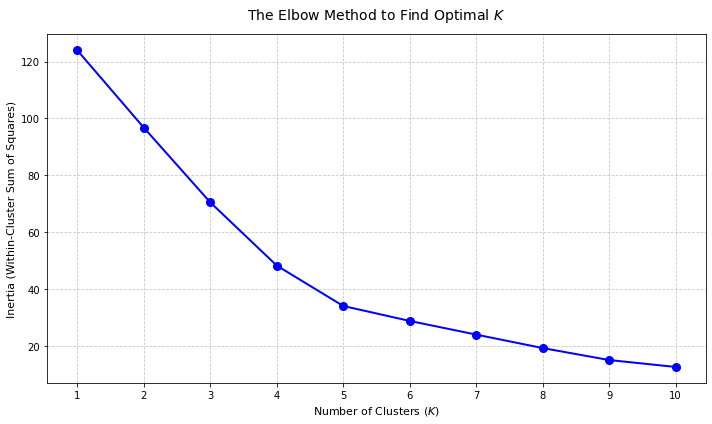

In [21]:
import threadpoolctl

class DummyLimits:
    def __init__(self, *args, **kwargs):
        pass
    def __enter__(self):
        return self
    def __exit__(self, exc_type, exc_val, exc_tb):
        pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 2. Prepare working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 3. Impute missing values and scale features
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Calculate Inertia for K values ranging from 1 to 10
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

# 5. Plot the Elbow Curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('The Elbow Method to Find Optimal $K$', fontsize=14, pad=15)
plt.xlabel('Number of Clusters ($K$)', fontsize=11)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

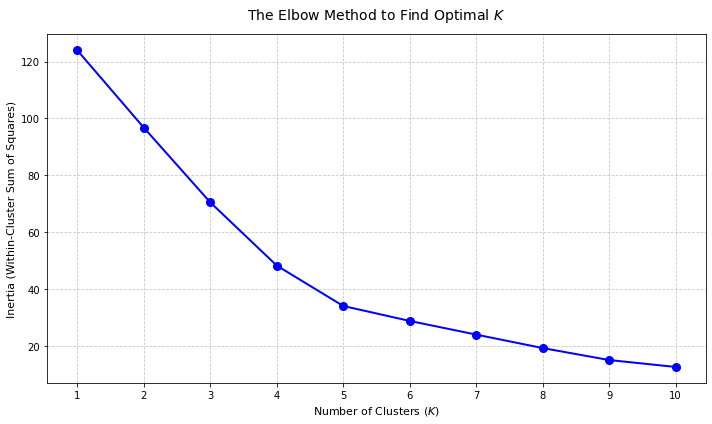

In [20]:
import threadpoolctl

class DummyLimits:
    def __init__(self, *args, **kwargs):
        pass
    def __enter__(self):
        return self
    def __exit__(self, exc_type, exc_val, exc_tb):
        pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 2. Prepare working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 3. Impute missing values and scale features
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Calculate Inertia for K values ranging from 1 to 10
inertia = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

# 5. Plot the Elbow Curve
plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('The Elbow Method to Find Optimal $K$', fontsize=14, pad=15)
plt.xlabel('Number of Clusters ($K$)', fontsize=11)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

So our optimal number of k is 5 or 6, we will look both of them.

      MULTI-VARIABLE HIERARCHICAL CLUSTERING RESULTS (6 CLUSTERS)      

Cluster 1 (12 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.5% | Infl: 4.0%
   • Denmark         | GDP: $351,030,642,724 | Unemp: 5.1% | Infl: 3.3%
   • Czechia         | GDP: $220,242,240,981 | Unemp: 2.6% | Infl: 10.7%
   • Finland         | GDP: $252,373,129,874 | Unemp: 7.1% | Infl: 6.3%
   • France          | GDP: $2,688,358,302,961 | Unemp: 7.3% | Infl: 4.9%
   • Germany         | GDP: $3,695,372,350,062 | Unemp: 3.1% | Infl: 5.9%
   • Italy           | GDP: $2,018,541,223,675 | Unemp: 7.6% | Infl: 5.6%
   • Mexico          | GDP: $1,327,845,439,048 | Unemp: 2.8% | Infl: 5.5%
   • Poland          | GDP: $638,740,867,489 | Unemp: 2.7% | Infl: 11.5%
   • Romania         | GDP: $235,229,078,940 | Unemp: 5.6% | Infl: 10.4%
   • Sweden          | GDP: $568,322,714,848 | Unemp: 7.6% | Infl: 8.5%

Cluster 2 (5 countries):


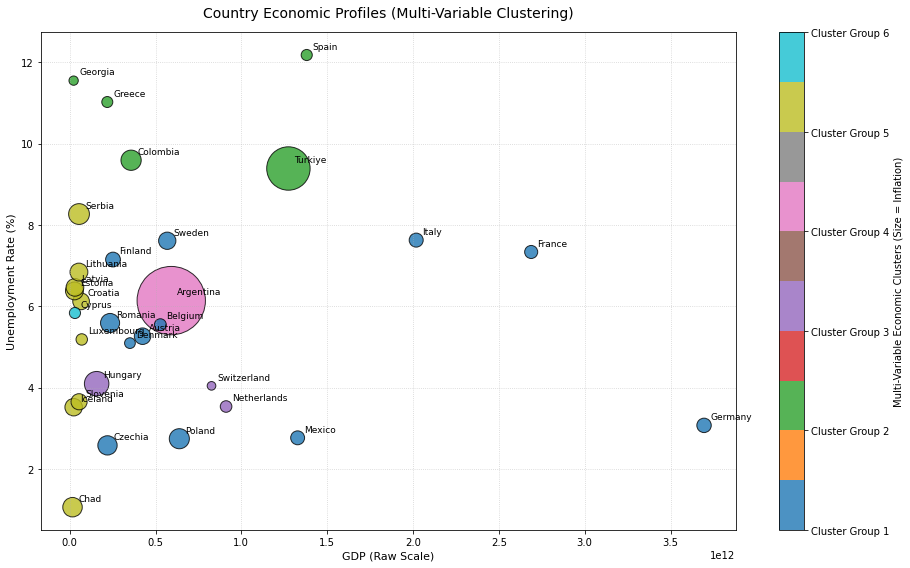

In [26]:
# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]" # Replace if you use a different 4th indicator

# Make a working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

# Features used for the machine learning model (all 4 dimensions)
model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 2. Impute missing values (so no countries get dropped)
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

# 3. Scale all features equally
scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Run Hierarchical Clustering (let's use 6 clusters)
n_clusters = 6
clustering = AgglomerativeClustering(n_clusters=n_clusters, affinity='euclidean', linkage='ward')
df_multi['Cluster'] = clustering.fit_predict(scaled_features)

# 5. Plot the Multi-Dimensional Clusters in 2D Space
plt.figure(figsize=(13, 8))

# Scale inflation for bubble size
bubble_sizes = df_multi[inflation_col].fillna(5) * 35 

scatter = plt.scatter(
    df_multi[gdp_col],           # Displaying raw GDP on X-axis for readability
    df_multi[unemp_col],         # Unemployment on Y-axis
    c=df_multi['Cluster'],       # Colored by the 4-indicator cluster result
    cmap='tab10', 
    s=bubble_sizes,              # Sized by inflation
    edgecolors='black', 
    alpha=0.8
)

# Annotate each country clearly
for _, row in df_multi.iterrows():
    plt.annotate(
        row["Country Name"], 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )
    
print(f"      MULTI-VARIABLE HIERARCHICAL CLUSTERING RESULTS ({n_clusters} CLUSTERS)      ")
print("=" * 85)
for cluster_id in range(n_clusters):
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    print(f"\nCluster {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%")
print("-" * 85)

# Formatting the legend/colorbar
cbar = plt.colorbar(scatter, ticks=range(n_clusters))
cbar.ax.set_yticklabels([f'Cluster Group {i+1}' for i in range(n_clusters)])
cbar.set_label('Multi-Variable Economic Clusters (Size = Inflation)', fontsize=10)

plt.title('Country Economic Profiles (Multi-Variable Clustering)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

This model has lots of flaws like look at the clusters, all of them are in different places which causes really complicated chart. Except that problem we can see that Grouping in some places is really great but other places are kind of off, for example Hungary is being in same cluster Switzerland and Netherlands. So I guess we need to try different algorithms because K-Means is not enough to solve this problem.

#### First Approach : DBSCAN
**DBSCAN** is a algorithm that uses density instead of distance. It defines clusters based on density of the data in that region. It uses two settings; one is **Epsilon (eps)** it determines how points should be close to each other. and the other is **MinSamples** it is the minimum number of elements to form a cluster. It works like first scanning data points and finding other data points and forms a core cluster and keep expands outside to neighbors who are not exceeding 

DBSCAN is really great with macro data, so it is very useful for us here.There are three reasons for that, one is that if a data point is an outlier it does not force into a group, it just basically labels it as noise. Also we don't have to determine a "k" value before performing algorithms. The bad part is to you have to tune the distance parameters really good to separate densities.

#### Another approach : Gaussian Mixture Models (GMM) / Soft Clustering

K-Means and hierarchical algorithms uses hard assignments, so it means that a data point needs to be belong %100 on some group so it forces data points into be in a group. 

GMM is based on probability so it assumes that data points are generated from a several Gaussian distributions.It calculates the probability that a given data point belongs to each cluster.

It is good for this data because in real life you can't put economies in a box. In real life there might be lots of different political and historical; sometimes even geographical stuff going in the back of the data and the results of the economies. It also allows clusters to be elliptical and strected shapes then forcing them to be strict circles like K-Means.


In [27]:
import os
import threadpoolctl

# Apply the same threadpool safety patches for Windows
class DummyLimits:
    def __init__(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, exc_type, exc_val, exc_tb): pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 2. Prepare working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 3. Impute missing values and scale features 
# (Scaling is extra critical for DBSCAN since it measures pure spatial distance)
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Run DBSCAN 
# eps: neighborhood radius size (adjust this if you get too many/few clusters)
# min_samples: minimum countries required to form a dense cluster
dbscan = DBSCAN(eps=1.3, min_samples=2)
df_multi['Cluster'] = dbscan.fit_predict(scaled_features)

# 5. Print the results (Cluster -1 represents Outliers / Noise)
clusters = sorted(df_multi['Cluster'].unique())
print("=" * 85)
print(f"      DBSCAN MACROECONOMIC CLUSTERING RESULTS      ")
print("=" * 85)

for cluster_id in clusters:
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    if cluster_id == -1:
        title = "Outliers / Isolated Anomalies (Noise (-1))"
    else:
        title = f"Cluster Group {cluster_id + 1}"
        
    print(f"\n{title} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%")
print("-" * 85)

      DBSCAN MACROECONOMIC CLUSTERING RESULTS      

Outliers / Isolated Anomalies (Noise (-1)) (4 countries):
   • Argentina       | GDP: $591,684,674,129 | Unemp: 6.1% | Infl: 133.5%
   • Cyprus          | GDP: $30,668,288,121 | Unemp: 5.8% | Infl: 3.5%
   • Georgia         | GDP: $22,963,990,777 | Unemp: 11.5% | Infl: 2.5%
   • Turkiye         | GDP: $1,274,162,834,490 | Unemp: 9.4% | Infl: 53.9%

Cluster Group 1 (27 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.5% | Infl: 4.0%
   • Chad            | GDP: $16,556,157,862 | Unemp: 1.1% | Infl: 10.8%
   • Croatia         | GDP: $66,484,829,952 | Unemp: 6.1% | Infl: 7.9%
   • Colombia        | GDP: $357,739,280,193 | Unemp: 9.6% | Infl: 11.7%
   • Denmark         | GDP: $351,030,642,724 | Unemp: 5.1% | Infl: 3.3%
   • Czechia         | GDP: $220,242,240,981 | Unemp: 2.6% | Infl: 10.7%
   • Estonia         | GDP: $27,578,887,219 | Unemp: 6.4% |

Here the DBSCAN actually did a great job while catching outliers. But it just put all of the other countries into one giant cluster, the reason for that is the "eps" parameter which works kind of like centroid mechanism in K-Means clustering. Now we will make it lower to have other clusters.

In [28]:
class DummyLimits:
    def __init__(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, exc_type, exc_val, exc_tb): pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 2. Prepare working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 3. Impute missing values and scale features 
# (Scaling is extra critical for DBSCAN since it measures pure spatial distance)
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Run DBSCAN 
# eps: neighborhood radius size (adjust this if you get too many/few clusters)
# min_samples: minimum countries required to form a dense cluster
dbscan = DBSCAN(eps=0.9, min_samples=2)
df_multi['Cluster'] = dbscan.fit_predict(scaled_features)

# 5. Print the results (Cluster -1 represents Outliers / Noise)
clusters = sorted(df_multi['Cluster'].unique())
print("=" * 85)
print(f"      DBSCAN MACROECONOMIC CLUSTERING RESULTS      ")
print("=" * 85)

for cluster_id in clusters:
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    if cluster_id == -1:
        title = "Outliers / Isolated Anomalies (Noise (-1))"
    else:
        title = f"Cluster Group {cluster_id + 1}"
        
    print(f"\n{title} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%")
print("-" * 85)

      DBSCAN MACROECONOMIC CLUSTERING RESULTS      

Outliers / Isolated Anomalies (Noise (-1)) (10 countries):
   • Argentina       | GDP: $591,684,674,129 | Unemp: 6.1% | Infl: 133.5%
   • Chad            | GDP: $16,556,157,862 | Unemp: 1.1% | Infl: 10.8%
   • Cyprus          | GDP: $30,668,288,121 | Unemp: 5.8% | Infl: 3.5%
   • Georgia         | GDP: $22,963,990,777 | Unemp: 11.5% | Infl: 2.5%
   • Hungary         | GDP: $157,072,489,604 | Unemp: 4.1% | Infl: 17.1%
   • Luxembourg      | GDP: $70,256,893,052 | Unemp: 5.2% | Infl: 3.7%
   • Netherlands     | GDP: $911,031,844,894 | Unemp: 3.5% | Infl: 3.8%
   • Spain           | GDP: $1,380,882,052,539 | Unemp: 12.2% | Infl: 3.5%
   • Switzerland     | GDP: $826,197,715,652 | Unemp: 4.0% | Infl: 2.1%
   • Turkiye         | GDP: $1,274,162,834,490 | Unemp: 9.4% | Infl: 53.9%

Cluster Group 1 (15 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.

And here having 10 outliers (noise) is not something we can be proud of whle using DBSCAN because even though Turkiye and Argentina make sense Netherlands and Spain does not. The reason for that is to decreasing eps way much more than it is supposed to, so now we will try eith 1.05, if still there is problem then we wll make it 1.10. If nothing works then we will go to Gaussian model.

In [33]:
class DummyLimits:
    def __init__(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, exc_type, exc_val, exc_tb): pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 2. Prepare working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 3. Impute missing values and scale features 
# (Scaling is extra critical for DBSCAN since it measures pure spatial distance)
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Run DBSCAN 
# eps: neighborhood radius size (adjust this if you get too many/few clusters)
# min_samples: minimum countries required to form a dense cluster
dbscan = DBSCAN(eps=1.1, min_samples=2)
df_multi['Cluster'] = dbscan.fit_predict(scaled_features)

# 5. Print the results (Cluster -1 represents Outliers / Noise)
clusters = sorted(df_multi['Cluster'].unique())
print("=" * 85)
print(f"      DBSCAN MACROECONOMIC CLUSTERING RESULTS      ")
print("=" * 85)

for cluster_id in clusters:
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    if cluster_id == -1:
        title = "Outliers / Isolated Anomalies (Noise (-1))"
    else:
        title = f"Cluster Group {cluster_id + 1}"
        
    print(f"\n{title} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%")
print("-" * 85)

      DBSCAN MACROECONOMIC CLUSTERING RESULTS      

Outliers / Isolated Anomalies (Noise (-1)) (7 countries):
   • Argentina       | GDP: $591,684,674,129 | Unemp: 6.1% | Infl: 133.5%
   • Cyprus          | GDP: $30,668,288,121 | Unemp: 5.8% | Infl: 3.5%
   • Georgia         | GDP: $22,963,990,777 | Unemp: 11.5% | Infl: 2.5%
   • Hungary         | GDP: $157,072,489,604 | Unemp: 4.1% | Infl: 17.1%
   • Netherlands     | GDP: $911,031,844,894 | Unemp: 3.5% | Infl: 3.8%
   • Spain           | GDP: $1,380,882,052,539 | Unemp: 12.2% | Infl: 3.5%
   • Turkiye         | GDP: $1,274,162,834,490 | Unemp: 9.4% | Infl: 53.9%

Cluster Group 1 (24 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.5% | Infl: 4.0%
   • Chad            | GDP: $16,556,157,862 | Unemp: 1.1% | Infl: 10.8%
   • Croatia         | GDP: $66,484,829,952 | Unemp: 6.1% | Infl: 7.9%
   • Colombia        | GDP: $357,739,280,193 | Unemp: 9.6

Here again it is not kind of a result we would love. So basically I can say that DBSCAN is not good for me because I am looking for economies and they need more attention and mode density than we have. So I will look for the graph of 0.9 eps DBSCAN and then we will move to Gaussian aşgorithm.

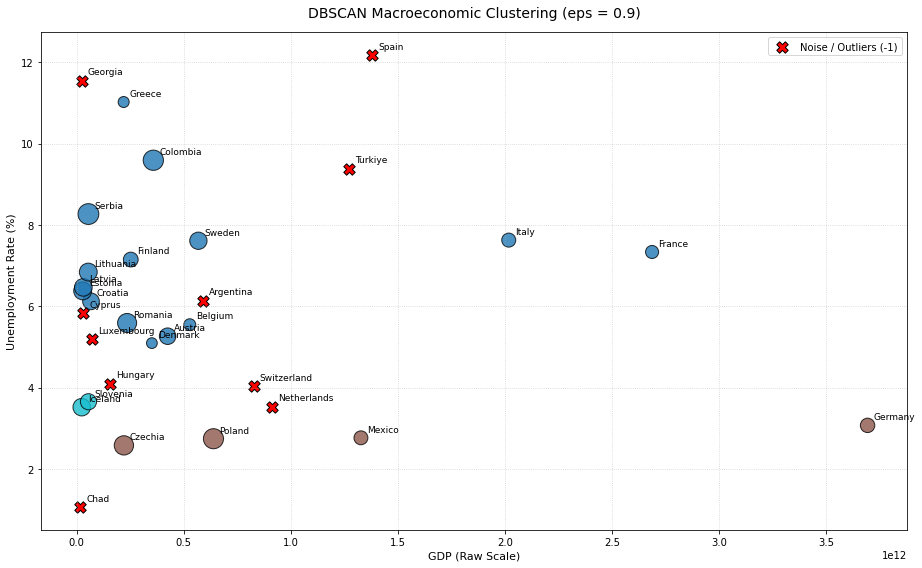

In [34]:
dbscan = DBSCAN(eps=0.9, min_samples=2)
df_multi['Cluster'] = dbscan.fit_predict(scaled_features)

# 5. Plotting the DBSCAN results
plt.figure(figsize=(13, 8))

core_points = df_multi[df_multi['Cluster'] != -1]
noise_points = df_multi[df_multi['Cluster'] == -1]

# Plot valid clusters
scatter = plt.scatter(
    core_points[gdp_col],
    core_points[unemp_col],
    c=core_points['Cluster'],
    cmap='tab10',
    s=core_points[inflation_col].fillna(5) * 35,
    edgecolors='black',
    alpha=0.8
)

# Plot noise/outliers as prominent red crosses
plt.scatter(
    noise_points[gdp_col],
    noise_points[unemp_col],
    color='red',
    marker='X',
    s=130,
    edgecolors='black',
    label='Noise / Outliers (-1)'
)

# Annotate each country clearly
for _, row in df_multi.iterrows():
    plt.annotate(
        row["Country Name"], 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )

plt.title('DBSCAN Macroeconomic Clustering (eps = 0.9)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


It is actually not that bad I am trying to find a model that can look at the data and put for example Germany as aoutlier and Italy and France in the same cluster, Switzerland and Netherlands at the same group, may be outlier Chad because it is the lowest of all. There is lots of corrections here but totally not so bad, could be better. So thats why I want to move to Gaussian.

In [35]:
import os
import threadpoolctl

# Maintain the threadpool safety patches for Windows
class DummyLimits:
    def __init__(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, exc_type, exc_val, exc_tb): pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.mixture import GaussianMixture
import numpy as np
import pandas as pd

# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]" 

# 2. Prepare working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 3. Impute missing values and scale features
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Fit Gaussian Mixture Model 
# n_components: Let's test with 5 clusters to give enough room for structural groupings
n_components = 5
gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=42)
df_multi['Cluster'] = gmm.fit_predict(scaled_features)

# Extract probabilities and log-densities to find structural outliers
probs = gmm.predict_proba(scaled_features)
df_multi['Max_Probability'] = probs.max(axis=1) # Confidence of assignment
df_multi['Log_Density'] = gmm.score_samples(scaled_features) # Overall data density fit

# 5. Print Structured Results
print("=" * 85)
print(f"      GAUSSIAN MIXTURE MODEL (GMM) RESULTS ({n_components} COMPONENTS)      ")
print("=" * 85)

for cluster_id in range(n_components):
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    print(f"\nCluster Group {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        conf = row['Max_Probability'] * 100
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%  (Confidence: {conf:.1f}%)")

print("\n" + "=" * 85)
print("      LOW-DENSITY STRUCTURAL OUTLIERS (Lowest Likelihood Scores)      ")
print("=" * 85)
# Sort by lowest log-density to see who sits furthest from normal distributions
outliers = df_multi.sort_values(by='Log_Density').head(5)
for _, row in outliers.iterrows():
    print(f"   ⚠️ {row['Country Name']:<15} | Log-Density Score: {row['Log_Density']:.2f} | GDP: ${row[gdp_col]:,.0f}")
print("-" * 85)

      GAUSSIAN MIXTURE MODEL (GMM) RESULTS (5 COMPONENTS)      

Cluster Group 1 (1 countries):
   • Cyprus          | GDP: $30,668,288,121 | Unemp: 5.8% | Infl: 3.5%  (Confidence: 100.0%)

Cluster Group 2 (16 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%  (Confidence: 100.0%)
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.5% | Infl: 4.0%  (Confidence: 100.0%)
   • Colombia        | GDP: $357,739,280,193 | Unemp: 9.6% | Infl: 11.7%  (Confidence: 100.0%)
   • Denmark         | GDP: $351,030,642,724 | Unemp: 5.1% | Infl: 3.3%  (Confidence: 100.0%)
   • Czechia         | GDP: $220,242,240,981 | Unemp: 2.6% | Infl: 10.7%  (Confidence: 100.0%)
   • Finland         | GDP: $252,373,129,874 | Unemp: 7.1% | Infl: 6.3%  (Confidence: 99.9%)
   • France          | GDP: $2,688,358,302,961 | Unemp: 7.3% | Infl: 4.9%  (Confidence: 100.0%)
   • Germany         | GDP: $3,695,372,350,062 | Unemp: 3.1% | Infl: 5.9%  (Confidence: 100.0%)
   • Greece          

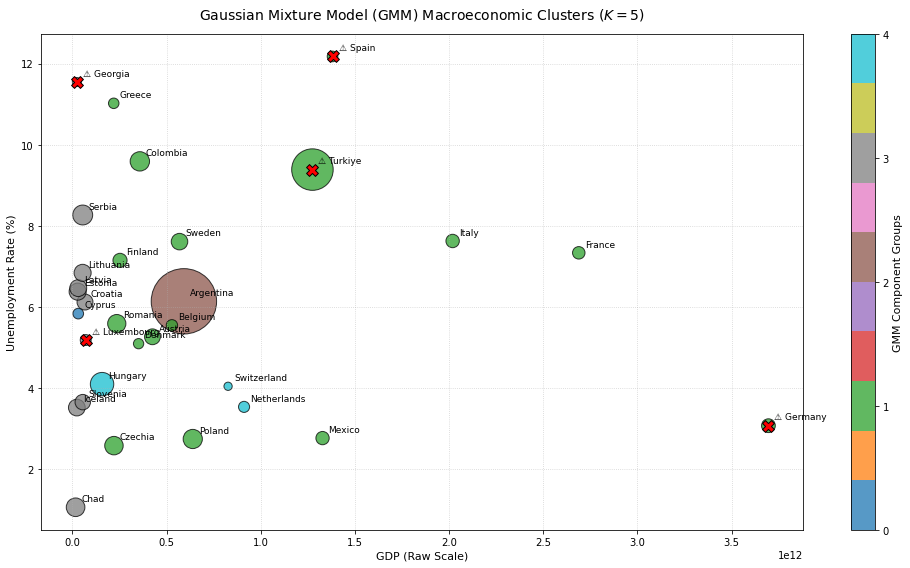

In [36]:

# 1. Set up the plotting canvas
plt.figure(figsize=(14, 8))

# 2. Scatter plot with GMM cluster assignments
scatter = plt.scatter(
    df_multi[gdp_col],
    df_multi[unemp_col],
    c=df_multi['Cluster'],
    cmap='tab10',
    s=df_multi[inflation_col].fillna(5) * 32, # Bubble size represents inflation severity
    edgecolors='black',
    alpha=0.75
)

# 3. Highlight top low-density structural outliers with a distinct marker
outlier_countries = outliers['Country Name'].tolist()
for _, row in df_multi.iterrows():
    if row['Country Name'] in outlier_countries:
        plt.scatter(
            row[gdp_col], 
            row[unemp_col], 
            color='red', 
            marker='X', 
            s=140, 
            edgecolors='black', 
            zorder=5
        )

# 4. Annotate all countries clearly
for _, row in df_multi.iterrows():
    # Add a visual warning tag for outliers in text
    label = f"⚠️ {row['Country Name']}" if row['Country Name'] in outlier_countries else row['Country Name']
    plt.annotate(
        label, 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )

# 5. Graph formatting and labels
plt.title('Gaussian Mixture Model (GMM) Macroeconomic Clusters ($K=5$)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# Add colorbar to represent the 5 GMM components
cbar = plt.colorbar(scatter, ticks=range(5))
cbar.set_label('GMM Component Groups', fontsize=11)

plt.tight_layout()
plt.show()

In Gaussian method we can see that some clusters are overlapping and it is normal because it looks for probabilities and it does not restrict itself with sphere-shaped clusters. It has soft assignment so there is no hard boundaries. In this model it is great to have Switzerland and Netherlands together, also it recognized Germany as an outlier. Those are the nice things but having one element clusters ar really not good may be they are some kind of outliers like here Argentina and Cyprus. Also we have really so much elements in one cluster group so I wil try to make this groupt ot be in pieces by increaseing the cluster numbers and also changing some of the parameters in the model. 

In [37]:
#starting with changing the number of clusters

class DummyLimits:
    def __init__(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, exc_type, exc_val, exc_tb): pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.mixture import GaussianMixture
import numpy as np
import pandas as pd

# 1. Define your multi-variable indicators 
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]" 

# 2. Prepare working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 3. Impute missing values and scale features
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Fit Gaussian Mixture Model 
n_components = 7
gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=42)
df_multi['Cluster'] = gmm.fit_predict(scaled_features)

# Extract probabilities and log-densities to find structural outliers
probs = gmm.predict_proba(scaled_features)
df_multi['Max_Probability'] = probs.max(axis=1) # Confidence of assignment
df_multi['Log_Density'] = gmm.score_samples(scaled_features) # Overall data density fit

# 5. Print Structured Results
print("=" * 85)
print(f"      GAUSSIAN MIXTURE MODEL (GMM) RESULTS ({n_components} COMPONENTS)      ")
print("=" * 85)

for cluster_id in range(n_components):
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    print(f"\nCluster Group {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        conf = row['Max_Probability'] * 100
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%  (Confidence: {conf:.1f}%)")

print("\n" + "=" * 85)
print("      LOW-DENSITY STRUCTURAL OUTLIERS (Lowest Likelihood Scores)      ")
print("=" * 85)
# Sort by lowest log-density to see who sits furthest from normal distributions
outliers = df_multi.sort_values(by='Log_Density').head(5)
for _, row in outliers.iterrows():
    print(f"   ⚠️ {row['Country Name']:<15} | Log-Density Score: {row['Log_Density']:.2f} | GDP: ${row[gdp_col]:,.0f}")
print("-" * 85)

      GAUSSIAN MIXTURE MODEL (GMM) RESULTS (7 COMPONENTS)      

Cluster Group 1 (1 countries):
   • Cyprus          | GDP: $30,668,288,121 | Unemp: 5.8% | Infl: 3.5%  (Confidence: 100.0%)

Cluster Group 2 (9 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%  (Confidence: 99.9%)
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.5% | Infl: 4.0%  (Confidence: 99.9%)
   • Denmark         | GDP: $351,030,642,724 | Unemp: 5.1% | Infl: 3.3%  (Confidence: 100.0%)
   • Czechia         | GDP: $220,242,240,981 | Unemp: 2.6% | Infl: 10.7%  (Confidence: 100.0%)
   • Finland         | GDP: $252,373,129,874 | Unemp: 7.1% | Infl: 6.3%  (Confidence: 100.0%)
   • Germany         | GDP: $3,695,372,350,062 | Unemp: 3.1% | Infl: 5.9%  (Confidence: 100.0%)
   • Mexico          | GDP: $1,327,845,439,048 | Unemp: 2.8% | Infl: 5.5%  (Confidence: 100.0%)
   • Poland          | GDP: $638,740,867,489 | Unemp: 2.7% | Infl: 11.5%  (Confidence: 100.0%)
   • Romania         | 

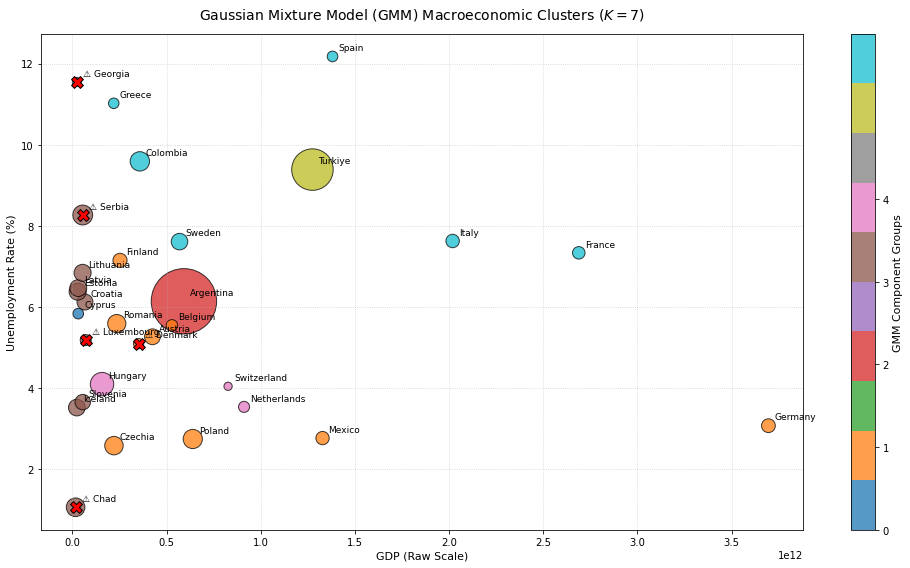

In [38]:
# 1. Set up the plotting canvas
plt.figure(figsize=(14, 8))

# 2. Scatter plot with GMM cluster assignments
scatter = plt.scatter(
    df_multi[gdp_col],
    df_multi[unemp_col],
    c=df_multi['Cluster'],
    cmap='tab10',
    s=df_multi[inflation_col].fillna(5) * 32, # Bubble size represents inflation severity
    edgecolors='black',
    alpha=0.75
)

# 3. Highlight top low-density structural outliers with a distinct marker
outlier_countries = outliers['Country Name'].tolist()
for _, row in df_multi.iterrows():
    if row['Country Name'] in outlier_countries:
        plt.scatter(
            row[gdp_col], 
            row[unemp_col], 
            color='red', 
            marker='X', 
            s=140, 
            edgecolors='black', 
            zorder=5
        )

# 4. Annotate all countries clearly
for _, row in df_multi.iterrows():
    # Add a visual warning tag for outliers in text
    label = f"⚠️ {row['Country Name']}" if row['Country Name'] in outlier_countries else row['Country Name']
    plt.annotate(
        label, 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )

# 5. Graph formatting and labels
plt.title('Gaussian Mixture Model (GMM) Macroeconomic Clusters ($K=7$)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# Add colorbar to represent the 5 GMM components
cbar = plt.colorbar(scatter, ticks=range(5))
cbar.set_label('GMM Component Groups', fontsize=11)

plt.tight_layout()
plt.show()

I think here we are really close to a great result.However we still have some problems.

#### Good Parts

Extreme ourliers like Turkiye and Argentina are has their own clusters. Because they have some other problems this shows us that we have really great grasp of the data. And group 2 consists of manufacturer and industrial economies like Germany,Denmark,Austria etc... This shows that we also have a great job here. And the Group / shows us the south and eastern European problems after the pandemic which is unemployment. 

Those are really nice because we can see that there is a model which can understand the economics however it does not ends here. 

#### Bad Parts

Economcially Chad and Luxemburg being in the same group is not what we could expect however we see in the graph that Chad has been eliminated because it is a low density outlier here and we can see that it is an outlier even if there wasn't a big X on it. Romania and Mexico being in the same group with Germany, Poland; Chezcia is not great because Romania is a developing country in Europe and Mexico is also another developing country in South America. Also Cyprus being a single group is not very good but I can understand because it the only country here that most of it's GDP comes from tourism. If we had Montenegro may be they could be in the same group.

## How can we make a better one

The best way to fix those problems is to use GDP per capita. But in this dataset we dont have this column. Instead of that we can use other columns we have to get a better clustering.

In [40]:
# 1. Update your indicator variables to include Trade and Growth
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
growth_col = "GDP growth (annual %) [NY.GDP.MKTP.KD.ZG]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
trade_col = "Trade (% of GDP) [NE.TRD.GNFS.ZS]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 2. Re-define your model features with trade openness and growth momentum
model_features = ['Log_GDP', growth_col, unemp_col, inflation_col, trade_col, fdi_col]

# 3. Impute missing values and scale features
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 4. Fit Gaussian Mixture Model 
n_components = 7
gmm = GaussianMixture(n_components=n_components, covariance_type='full', random_state=42)
df_multi['Cluster'] = gmm.fit_predict(scaled_features)

# Extract probabilities and log-densities to find structural outliers
probs = gmm.predict_proba(scaled_features)
df_multi['Max_Probability'] = probs.max(axis=1) # Confidence of assignment
df_multi['Log_Density'] = gmm.score_samples(scaled_features) # Overall data density fit

# 5. Print Structured Results
print("=" * 85)
print(f"      GAUSSIAN MIXTURE MODEL (GMM) RESULTS ({n_components} COMPONENTS)      ")
print("=" * 85)

for cluster_id in range(n_components):
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    print(f"\nCluster Group {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        conf = row['Max_Probability'] * 100
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%  (Confidence: {conf:.1f}%)")

print("\n" + "=" * 85)
print("      LOW-DENSITY STRUCTURAL OUTLIERS (Lowest Likelihood Scores)      ")
print("=" * 85)
# Sort by lowest log-density to see who sits furthest from normal distributions
outliers = df_multi.sort_values(by='Log_Density').head(5)
for _, row in outliers.iterrows():
    print(f"   ⚠️ {row['Country Name']:<15} | Log-Density Score: {row['Log_Density']:.2f} | GDP: ${row[gdp_col]:,.0f}")
print("-" * 85)

      GAUSSIAN MIXTURE MODEL (GMM) RESULTS (7 COMPONENTS)      

Cluster Group 1 (1 countries):
   • Cyprus          | GDP: $30,668,288,121 | Unemp: 5.8% | Infl: 3.5%  (Confidence: 100.0%)

Cluster Group 2 (9 countries):
   • Colombia        | GDP: $357,739,280,193 | Unemp: 9.6% | Infl: 11.7%  (Confidence: 100.0%)
   • France          | GDP: $2,688,358,302,961 | Unemp: 7.3% | Infl: 4.9%  (Confidence: 100.0%)
   • Germany         | GDP: $3,695,372,350,062 | Unemp: 3.1% | Infl: 5.9%  (Confidence: 100.0%)
   • Greece          | GDP: $219,083,738,943 | Unemp: 11.0% | Infl: 3.5%  (Confidence: 100.0%)
   • Italy           | GDP: $2,018,541,223,675 | Unemp: 7.6% | Infl: 5.6%  (Confidence: 100.0%)
   • Romania         | GDP: $235,229,078,940 | Unemp: 5.6% | Infl: 10.4%  (Confidence: 98.7%)
   • Spain           | GDP: $1,380,882,052,539 | Unemp: 12.2% | Infl: 3.5%  (Confidence: 100.0%)
   • Sweden          | GDP: $568,322,714,848 | Unemp: 7.6% | Infl: 8.5%  (Confidence: 100.0%)
   • Turkiye    

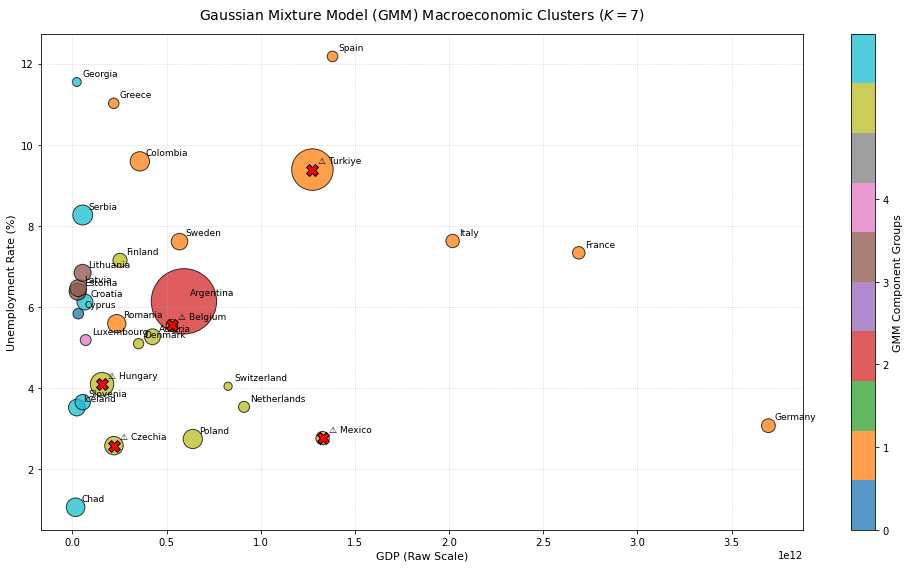

In [41]:
# 1. Set up the plotting canvas
plt.figure(figsize=(14, 8))

# 2. Scatter plot with GMM cluster assignments
scatter = plt.scatter(
    df_multi[gdp_col],
    df_multi[unemp_col],
    c=df_multi['Cluster'],
    cmap='tab10',
    s=df_multi[inflation_col].fillna(5) * 32, # Bubble size represents inflation severity
    edgecolors='black',
    alpha=0.75
)

# 3. Highlight top low-density structural outliers with a distinct marker
outlier_countries = outliers['Country Name'].tolist()
for _, row in df_multi.iterrows():
    if row['Country Name'] in outlier_countries:
        plt.scatter(
            row[gdp_col], 
            row[unemp_col], 
            color='red', 
            marker='X', 
            s=140, 
            edgecolors='black', 
            zorder=5
        )

# 4. Annotate all countries clearly
for _, row in df_multi.iterrows():
    # Add a visual warning tag for outliers in text
    label = f"⚠️ {row['Country Name']}" if row['Country Name'] in outlier_countries else row['Country Name']
    plt.annotate(
        label, 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), 
        textcoords="offset points",
        fontsize=9,
        fontweight="medium"
    )

# 5. Graph formatting and labels
plt.title('Gaussian Mixture Model (GMM) Macroeconomic Clusters ($K=7$)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)

# Add colorbar to represent the 5 GMM components
cbar = plt.colorbar(scatter, ticks=range(5))
cbar.set_label('GMM Component Groups', fontsize=11)

plt.tight_layout()
plt.show()

#### What are the great things about this model?

First of all, baltics are in same cluster this is great because they are similar and in the same area as you can see. Also we can see that Mexico, Hungary, Czechia and Austria are being outliers and being out of the cluster group 6 is really good because when you make them go away you can see that remaining countries are really similar except Poland.

#### What are the bad things about this model?

Unfortunately Chad being in cluster 7 is bad because actually it is an outlier and a bad one so actually it does not belong any other cluster. It might have been out of the clustering or has to be a singleton. Not a really bad result but could have been better.

  WEIGHTED GAUSSIAN MIXTURE MODEL (GMM - DIAG) RESULTS (K=7)  

Cluster Group 1 (1 countries):
   • Cyprus          | GDP: $30,668,288,121 | Unemp: 5.8% | Infl: 3.5%  (Conf: 100.0%)

Cluster Group 2 (10 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%  (Conf: 100.0%)
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.5% | Infl: 4.0%  (Conf: 100.0%)
   • Colombia        | GDP: $357,739,280,193 | Unemp: 9.6% | Infl: 11.7%  (Conf: 100.0%)
   • Denmark         | GDP: $351,030,642,724 | Unemp: 5.1% | Infl: 3.3%  (Conf: 100.0%)
   • Czechia         | GDP: $220,242,240,981 | Unemp: 2.6% | Infl: 10.7%  (Conf: 99.9%)
   • Finland         | GDP: $252,373,129,874 | Unemp: 7.1% | Infl: 6.3%  (Conf: 100.0%)
   • Greece          | GDP: $219,083,738,943 | Unemp: 11.0% | Infl: 3.5%  (Conf: 100.0%)
   • Poland          | GDP: $638,740,867,489 | Unemp: 2.7% | Infl: 11.5%  (Conf: 100.0%)
   • Romania         | GDP: $235,229,078,940 | Unemp: 5.6% | Infl: 10.4%  (Con

Text(0.5, 1.0, 'Weighted GMM Macroeconomic Clusters (K=7, Diagonal Covariance)')

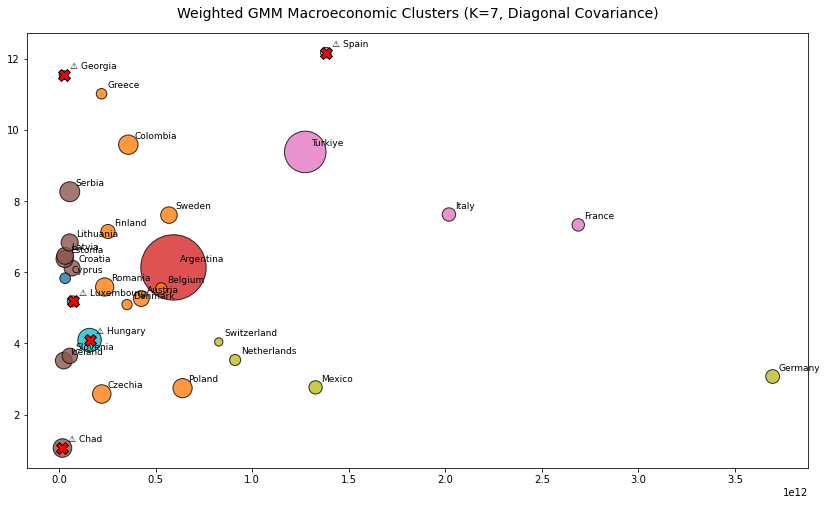

In [43]:
import os
import threadpoolctl

# 1. Threadpool safety patch for Windows environments
class DummyLimits:
    def __init__(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, exc_type, exc_val, exc_tb): pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 2. Define clean, focused 4-indicator setup
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 3. Prepare working copy and log-transform GDP
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# 4. Impute missing values and scale features
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_multi[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# 5. Apply explicit Feature Weighting
# Weights order: [Log_GDP, Unemployment, Inflation, FDI]
# Increased weight on Log_GDP and Inflation prevents scale/price distortion
feature_weights = np.array([1.6, 1.0, 1.4, 0.8])
weighted_features = scaled_features * feature_weights

# 6. Fit GMM with K=7 and diagonal covariance to tighten cluster boundaries
n_components = 7
gmm = GaussianMixture(
    n_components=n_components, 
    covariance_type='diag', 
    random_state=42
)
df_multi['Cluster'] = gmm.fit_predict(weighted_features)

# Extract probabilistic metrics
probs = gmm.predict_proba(weighted_features)
df_multi['Max_Probability'] = probs.max(axis=1)
df_multi['Log_Density'] = gmm.score_samples(weighted_features)

# 7. Print Cluster Breakdowns
print("=" * 85)
print(f"  WEIGHTED GAUSSIAN MIXTURE MODEL (GMM - DIAG) RESULTS (K={n_components})  ")
print("=" * 85)

for cluster_id in range(n_components):
    cluster_countries = df_multi[df_multi['Cluster'] == cluster_id]
    print(f"\nCluster Group {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        conf = row['Max_Probability'] * 100
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%  (Conf: {conf:.1f}%)")

# Print density-based structural outliers
print("\n" + "=" * 85)
print("      LOW-DENSITY STRUCTURAL OUTLIERS (Lowest Likelihood Scores)      ")
print("=" * 85)
outliers = df_multi.sort_values(by='Log_Density').head(5)
for _, row in outliers.iterrows():
    print(f"   ⚠️ {row['Country Name']:<15} | Log-Density Score: {row['Log_Density']:.2f} | GDP: ${row[gdp_col]:,.0f}")
print("-" * 85)

# 8. Visualization Plot
plt.figure(figsize=(14, 8))

scatter = plt.scatter(
    df_multi[gdp_col],
    df_multi[unemp_col],
    c=df_multi['Cluster'],
    cmap='tab10',
    s=df_multi[inflation_col].fillna(5) * 32,
    edgecolors='black',
    alpha=0.8
)

# Highlight lowest density outliers with red X
outlier_names = outliers['Country Name'].tolist()
for _, row in df_multi.iterrows():
    if row['Country Name'] in outlier_names:
        plt.scatter(
            row[gdp_col], row[unemp_col], 
            color='red', marker='X', s=140, edgecolors='black', zorder=5
        )

# Annotate country labels
for _, row in df_multi.iterrows():
    label = f"⚠️ {row['Country Name']}" if row['Country Name'] in outlier_names else row['Country Name']
    plt.annotate(
        label, 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), textcoords="offset points",
        fontsize=9, fontweight="medium"
    )

plt.title('Weighted GMM Macroeconomic Clusters (K=7, Diagonal Covariance)', fontsize=14, pad=15)

This model is a major stepback because now clusters and outliers are really bad. Mexico being in the Swiss/Dutch group is really one of the worst thing can be happen. Also group 4 is really bad because Iceland, Slovenia and Chad are now in Baltic group and it does not have very common economic performance. Also Denmark,Sweden, Luxemburg and Finland being in the group 2 is complete disaster. 

### Why this happened?
Because we tried to gave strict feature weights but this model does not work like that. We over-complicated the model so it gives us such stupid result. 

To fix it we can first use hard quartine, so we will put a threshold for countries. After that we will make a clear GMM Clustering.

      TWO-STAGE PIPELINE: QUARANTINED STRUCTURAL OUTLIERS      
   🛑 Argentina       | GDP: $591,684,674,129 | Unemp: 6.1% | Infl: 133.5% (Quarantined)
   🛑 Turkiye         | GDP: $1,274,162,834,490 | Unemp: 9.4% | Infl: 53.9% (Quarantined)

      GMM CLUSTER RESULTS FOR STABLE ECONOMIES (K=7)      

Cluster Group 1 (9 countries):
   • Austria         | GDP: $424,607,814,489 | Unemp: 5.3% | Infl: 7.8%  (Conf: 100.0%)
   • Belgium         | GDP: $528,074,098,662 | Unemp: 5.5% | Infl: 4.0%  (Conf: 100.0%)
   • Denmark         | GDP: $351,030,642,724 | Unemp: 5.1% | Infl: 3.3%  (Conf: 100.0%)
   • Finland         | GDP: $252,373,129,874 | Unemp: 7.1% | Infl: 6.3%  (Conf: 100.0%)
   • France          | GDP: $2,688,358,302,961 | Unemp: 7.3% | Infl: 4.9%  (Conf: 100.0%)
   • Italy           | GDP: $2,018,541,223,675 | Unemp: 7.6% | Infl: 5.6%  (Conf: 100.0%)
   • Luxembourg      | GDP: $70,256,893,052 | Unemp: 5.2% | Infl: 3.7%  (Conf: 100.0%)
   • Netherlands     | GDP: $911,031,844,894 | U

C:\Users\Aleyna\AppData\Local\Temp\ipykernel_15924\2181530382.py:142: UserWarning: Glyph 128721 (\N{OCTAGONAL SIGN}) missing from current font.
  plt.tight_layout()
C:\Users\Aleyna\anaconda3\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: Glyph 128721 (\N{OCTAGONAL SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


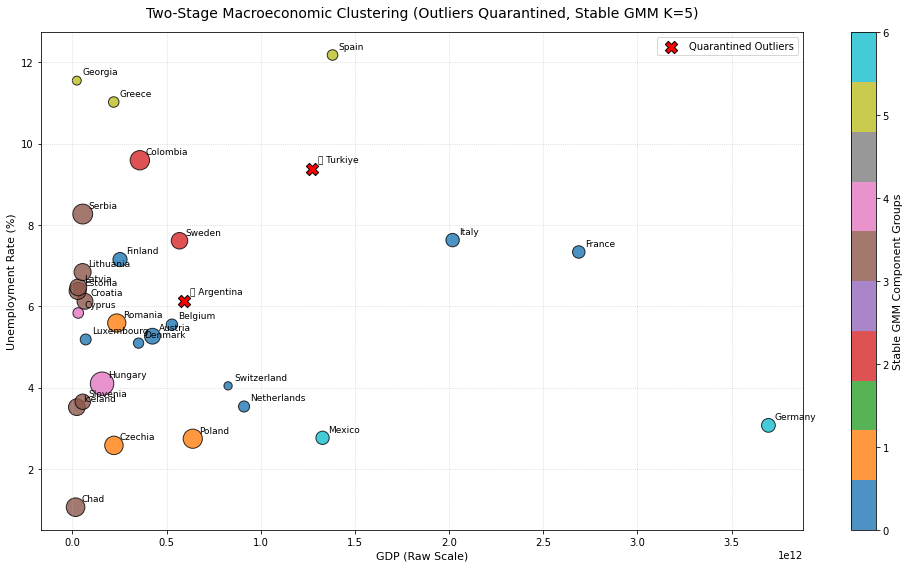

In [45]:
# Two Stage Pipeline

import os
import threadpoolctl

# 1. Threadpool safety patch for Windows environments
class DummyLimits:
    def __init__(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, exc_type, exc_val, exc_tb): pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 2. Define your indicators
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 3. Prepare working copy
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

# =====================================================================
# STAGE 1: HARD QUARANTINE OF EXTREME STRUCTURAL OUTLIERS
# =====================================================================
# Isolate hyperinflationary anomalies or extreme distortions upfront 
# so they don't corrupt the scaling or GMM bell curves for the rest of the world.
outlier_condition = (df_multi[inflation_col] > 30.0) # e.g., Argentina & Turkiye

df_quarantined = df_multi[outlier_condition].copy()
df_quarantined['Cluster'] = -1  # Designated outlier tag
df_quarantined['Max_Probability'] = 1.0

df_stable = df_multi[~outlier_condition].copy()

# =====================================================================
# STAGE 2: CLEAN GMM CLUSTERING ON STABLE / TRANSITIONAL ECONOMIES
# =====================================================================
model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# Impute and scale only the stable subset
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_stable[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# Run GMM on the clean subset (using K=5 or 6 since outliers are removed)
n_components = 7
gmm = GaussianMixture(
    n_components=n_components, 
    covariance_type='full', # Back to full/diag as preferred for natural shapes
    random_state=42
)
df_stable['Cluster'] = gmm.fit_predict(scaled_features)

# Calculate probabilities and densities for the stable group
probs = gmm.predict_proba(scaled_features)
df_stable['Max_Probability'] = probs.max(axis=1)
df_stable['Log_Density'] = gmm.score_samples(scaled_features)

# Combine datasets back together for unified reporting
df_multi_final = pd.concat([df_stable, df_quarantined])

# =====================================================================
# PRINT RESULTS
# =====================================================================
print("=" * 85)
print("      TWO-STAGE PIPELINE: QUARANTINED STRUCTURAL OUTLIERS      ")
print("=" * 85)
for _, row in df_quarantined.iterrows():
    print(f"   🛑 {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}% (Quarantined)")

print("\n" + "=" * 85)
print(f"      GMM CLUSTER RESULTS FOR STABLE ECONOMIES (K={n_components})      ")
print("=" * 85)

for cluster_id in range(n_components):
    cluster_countries = df_stable[df_stable['Cluster'] == cluster_id]
    print(f"\nCluster Group {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        conf = row['Max_Probability'] * 100
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%  (Conf: {conf:.1f}%)")

# =====================================================================
# VISUALIZATION PLOT
# =====================================================================
plt.figure(figsize=(14, 8))

# Plot stable clustered economies
scatter = plt.scatter(
    df_stable[gdp_col],
    df_stable[unemp_col],
    c=df_stable['Cluster'],
    cmap='tab10',
    s=df_stable[inflation_col].fillna(5) * 32,
    edgecolors='black',
    alpha=0.8
)

# Plot quarantined structural outliers with bold red X markers
plt.scatter(
    df_quarantined[gdp_col],
    df_quarantined[unemp_col],
    color='red',
    marker='X',
    s=150,
    edgecolors='black',
    zorder=5,
    label='Quarantined Outliers'
)

# Annotate all countries
for _, row in df_multi_final.iterrows():
    is_q = row['Country Name'] in df_quarantined['Country Name'].values
    label = f"🛑 {row['Country Name']}" if is_q else row['Country Name']
    plt.annotate(
        label, 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), textcoords="offset points",
        fontsize=9, fontweight="medium"
    )

plt.title('Two-Stage Macroeconomic Clustering (Outliers Quarantined, Stable GMM K=5)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

cbar = plt.colorbar(scatter, ticks=range(n_components))
cbar.set_label('Stable GMM Component Groups', fontsize=11)

plt.tight_layout()
plt.show()

Actually this model is pretty great but it has flaws as everyone else.. Our problem here is that Mexico and Germany cluster and colombia / Sweden cluster. Except that everything kind of looks great, not major problems. I can fix this problems by increasing log-gdp value to differentiate Mexico and Germany and for Columbia and Sweden I will decrease the cluster number to 6.

      TWO-STAGE PIPELINE: QUARANTINED STRUCTURAL OUTLIERS      
   🛑 Argentina       | GDP: $591,684,674,129 | Unemp: 6.1% | Infl: 133.5% (Quarantined)
   🛑 Turkiye         | GDP: $1,274,162,834,490 | Unemp: 9.4% | Infl: 53.9% (Quarantined)

      GMM CLUSTER RESULTS FOR STABLE ECONOMIES (K=8)      

Cluster Group 1 (6 countries):
   • Denmark         | GDP: $351,030,642,724 | Unemp: 5.1% | Infl: 3.3%  (Conf: 100.0%)
   • Germany         | GDP: $3,695,372,350,062 | Unemp: 3.1% | Infl: 5.9%  (Conf: 100.0%)
   • Luxembourg      | GDP: $70,256,893,052 | Unemp: 5.2% | Infl: 3.7%  (Conf: 100.0%)
   • Mexico          | GDP: $1,327,845,439,048 | Unemp: 2.8% | Infl: 5.5%  (Conf: 100.0%)
   • Netherlands     | GDP: $911,031,844,894 | Unemp: 3.5% | Infl: 3.8%  (Conf: 100.0%)
   • Switzerland     | GDP: $826,197,715,652 | Unemp: 4.0% | Infl: 2.1%  (Conf: 100.0%)

Cluster Group 2 (2 countries):
   • Czechia         | GDP: $220,242,240,981 | Unemp: 2.6% | Infl: 10.7%  (Conf: 100.0%)
   • Poland    

C:\Users\Aleyna\AppData\Local\Temp\ipykernel_15924\3502159518.py:137: UserWarning: Glyph 128721 (\N{OCTAGONAL SIGN}) missing from current font.
  plt.tight_layout()
C:\Users\Aleyna\anaconda3\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: Glyph 128721 (\N{OCTAGONAL SIGN}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


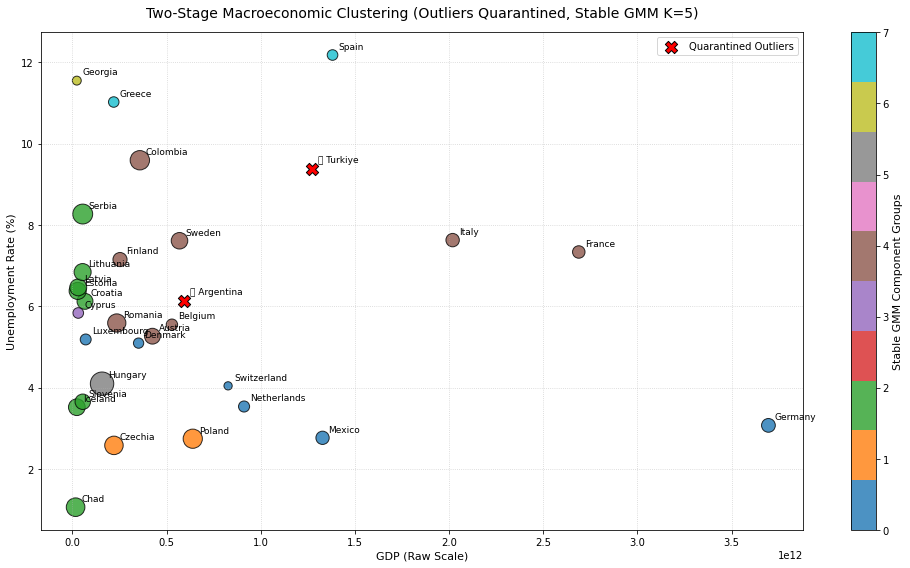

In [48]:
# 1. Threadpool safety patch for Windows environments
class DummyLimits:
    def __init__(self, *args, **kwargs): pass
    def __enter__(self): return self
    def __exit__(self, exc_type, exc_val, exc_tb): pass

threadpoolctl.threadpool_limits = DummyLimits
threadpoolctl.threadpool_info = lambda: []

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 2. Define your indicators
gdp_col = "GDP (constant 2015 US$) [NY.GDP.MKTP.KD]"
unemp_col = "Unemployment, total (% of total labor force) (modeled ILO estimate) [SL.UEM.TOTL.ZS]"
inflation_col = "Inflation, consumer prices (annual %) [FP.CPI.TOTL.ZG]"
fdi_col = "Foreign direct investment, net inflows (% of GDP) [BX.KLT.DINV.WD.GD.ZS]"

# 3. Prepare working copy
df_multi = df_filtered.dropna(subset=["Country Name"]).copy()
df_multi['Log_GDP'] = np.log(df_multi[gdp_col])

# =====================================================================
# STAGE 1: HARD QUARANTINE OF EXTREME STRUCTURAL OUTLIERS
# =====================================================================
# Isolate hyperinflationary anomalies or extreme distortions upfront 
# so they don't corrupt the scaling or GMM bell curves for the rest of the world.
outlier_condition = (df_multi[inflation_col] > 30.0) # e.g., Argentina & Turkiye

df_quarantined = df_multi[outlier_condition].copy()
df_quarantined['Cluster'] = -1  # Designated outlier tag
df_quarantined['Max_Probability'] = 1.8

df_stable = df_multi[~outlier_condition].copy()

# =====================================================================
# STAGE 2: CLEAN GMM CLUSTERING ON STABLE / TRANSITIONAL ECONOMIES
# =====================================================================
model_features = ['Log_GDP', unemp_col, inflation_col, fdi_col]

# Impute and scale only the stable subset
imputer = SimpleImputer(strategy='median')
imputed_data = imputer.fit_transform(df_stable[model_features])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(imputed_data)

# Run GMM on the clean subset (using K=5 or 6 since outliers are removed)
n_components = 8
gmm = GaussianMixture(
    n_components=n_components, 
    covariance_type='full', # Back to full/diag as preferred for natural shapes
    random_state=42
)
df_stable['Cluster'] = gmm.fit_predict(scaled_features)

# Calculate probabilities and densities for the stable group
probs = gmm.predict_proba(scaled_features)
df_stable['Max_Probability'] = probs.max(axis=1)
df_stable['Log_Density'] = gmm.score_samples(scaled_features)

# Combine datasets back together for unified reporting
df_multi_final = pd.concat([df_stable, df_quarantined])

# =====================================================================
# PRINT RESULTS
# =====================================================================
print("=" * 85)
print("      TWO-STAGE PIPELINE: QUARANTINED STRUCTURAL OUTLIERS      ")
print("=" * 85)
for _, row in df_quarantined.iterrows():
    print(f"   🛑 {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}% (Quarantined)")

print("\n" + "=" * 85)
print(f"      GMM CLUSTER RESULTS FOR STABLE ECONOMIES (K={n_components})      ")
print("=" * 85)

for cluster_id in range(n_components):
    cluster_countries = df_stable[df_stable['Cluster'] == cluster_id]
    print(f"\nCluster Group {cluster_id + 1} ({len(cluster_countries)} countries):")
    for _, row in cluster_countries.iterrows():
        conf = row['Max_Probability'] * 100
        print(f"   • {row['Country Name']:<15} | GDP: ${row[gdp_col]:,.0f} | Unemp: {row[unemp_col]:.1f}% | Infl: {row[inflation_col]:.1f}%  (Conf: {conf:.1f}%)")

# =====================================================================
# VISUALIZATION PLOT
# =====================================================================
plt.figure(figsize=(14, 8))

# Plot stable clustered economies
scatter = plt.scatter(
    df_stable[gdp_col],
    df_stable[unemp_col],
    c=df_stable['Cluster'],
    cmap='tab10',
    s=df_stable[inflation_col].fillna(5) * 32,
    edgecolors='black',
    alpha=0.8
)

# Plot quarantined structural outliers with bold red X markers
plt.scatter(
    df_quarantined[gdp_col],
    df_quarantined[unemp_col],
    color='red',
    marker='X',
    s=150,
    edgecolors='black',
    zorder=5,
    label='Quarantined Outliers'
)

# Annotate all countries
for _, row in df_multi_final.iterrows():
    is_q = row['Country Name'] in df_quarantined['Country Name'].values
    label = f"🛑 {row['Country Name']}" if is_q else row['Country Name']
    plt.annotate(
        label, 
        (row[gdp_col], row[unemp_col]),
        xytext=(6, 6), textcoords="offset points",
        fontsize=9, fontweight="medium"
    )

plt.title('Two-Stage Macroeconomic Clustering (Outliers Quarantined, Stable GMM K=5)', fontsize=14, pad=15)
plt.xlabel('GDP (Raw Scale)', fontsize=11)
plt.ylabel('Unemployment Rate (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

cbar = plt.colorbar(scatter, ticks=range(n_components))
cbar.set_label('Stable GMM Component Groups', fontsize=11)

plt.tight_layout()
plt.show()

After I decreased the number of cluters and increased the threshold for the log-gdp still something was missing. So I tried to increase the number of clusters to 8, with that I got a really great result. For ezample Czechia dn Poland are togerhet which makes the most sense of the world. After that there are also Cluster 1 which is the best clıster ever except MExico. I it so neatly organized that when I first saw it I was like WHATTTTTT???? Also our singletons did a great job because I am not sure of Hungary but Cyprus is a tourism economy and Georgia is not in a great shape. And also group 8, where Greece and Spain are together makes total sense because they have problems in their economies and especially after pandemic. 

## What is my final call?

Actually I really liked this model, yes it has its flaws but the real reason for that flaws is that I got different countries and different reagions so this is normal. You might ask that "What did you expect? You have to be able to get a clustering algırithm that can really differentiate regions etc.. but the thing that you are missing while asking this question that models can only understand what is happening on the data. Commenting and looking behind the data is the job of humans. AI can code and get results but it can not have the ability to think of itself about what is going on or what might be the reason for those results if you don't tell it. That's the difference between humans and AI. Even if one day they will get the World and everything still it can not replace humans because our brain is total mystery and we still not able to get it 100%.